Importing the dependencies

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso
from sklearn import metrics

Data Collection and Processing

In [3]:
# Loading the data from csv file to pandas DataFrame 
car_dataset = pd.read_csv('Car_Price_Prediction.csv')

In [4]:
# Inspecting the first 5 rows of the dataFrame
car_dataset.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [5]:
# Checking the number of rows and columns
car_dataset.shape

(4340, 8)

In [6]:
# Getting some information about the dataset
car_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 271.4 KB


In [7]:
# Checking the number of missing value
car_dataset.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

In [8]:
# Checking the distribution of categorical data
print(car_dataset.fuel.value_counts())
print(car_dataset.seller_type.value_counts())
print(car_dataset.transmission.value_counts())
print(car_dataset.owner.value_counts())

fuel
Diesel      2153
Petrol      2123
CNG           40
LPG           23
Electric       1
Name: count, dtype: int64
seller_type
Individual          3244
Dealer               994
Trustmark Dealer     102
Name: count, dtype: int64
transmission
Manual       3892
Automatic     448
Name: count, dtype: int64
owner
First Owner             2832
Second Owner            1106
Third Owner              304
Fourth & Above Owner      81
Test Drive Car            17
Name: count, dtype: int64


Encoding the categorical Data

In [35]:
# encoding "fuel" Column
car_dataset.replace({'fuel':{'Diesel':0,'Petrol':1,'CNG':2,'LPG':3,'Electric':4}},inplace = True)

# encoding "seller_type" Column
car_dataset.replace({'seller_type':{'Individual':0,'Dealer':1,'Trustmark Dealer':2}},inplace = True)

# encoding "tranmission" Column
car_dataset.replace({'transmission':{'Manual':0,'Automatic':1}},inplace = True)

# encoding "owner" Column
car_dataset.replace({'owner':{'First Owner':0,'Second Owner':1,'Third Owner':2,'Fourth & Above Owner':3,'Test Drive Car':4}},inplace = True)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,1,0,0,0
1,Maruti Wagon R LXI Minor,2007,135000,50000,1,0,0,0
2,Hyundai Verna 1.6 SX,2012,600000,100000,0,0,0,0
3,Datsun RediGO T Option,2017,250000,46000,1,0,0,0
4,Honda Amaze VX i-DTEC,2014,450000,141000,0,0,0,1
...,...,...,...,...,...,...,...,...
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),2014,409999,80000,0,0,0,1
4336,Hyundai i20 Magna 1.4 CRDi,2014,409999,80000,0,0,0,1
4337,Maruti 800 AC BSIII,2009,110000,83000,1,0,0,1
4338,Hyundai Creta 1.6 CRDi SX Option,2016,865000,90000,0,0,0,0


Splitting the data and target

In [36]:
Y = car_dataset['selling_price']
X = car_dataset.drop(['name','selling_price'],axis = 1)

In [37]:
print(X)

      year  km_driven fuel seller_type transmission owner
0     2007      70000    1           0            0     0
1     2007      50000    1           0            0     0
2     2012     100000    0           0            0     0
3     2017      46000    1           0            0     0
4     2014     141000    0           0            0     1
...    ...        ...  ...         ...          ...   ...
4335  2014      80000    0           0            0     1
4336  2014      80000    0           0            0     1
4337  2009      83000    1           0            0     1
4338  2016      90000    0           0            0     0
4339  2016      40000    1           0            0     0

[4340 rows x 6 columns]


Splitting Training and test Data

In [38]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.1, random_state = 2)

Model Training

1. Linear Regression 

In [39]:
# loading the linear regression model 
lin_reg_model = LinearRegression() 

In [40]:
lin_reg_model.fit(X_train, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[ 37870.12, -0.75,-237031.62, 89281.28, 856758.91, -9897.32]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['year','km_driven','fuel','seller_type','transmission','owner']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-7.567e+07
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)


Model Evaluation

In [41]:
# Prediction on Training data
training_data_prediction = lin_reg_model.predict(X_train)

In [42]:
# R squared Error
error_score = metrics.r2_score(Y_train, training_data_prediction)
print("R squarred Error : ", error_score)

R squarred Error :  0.44307875879219427


Visualize the actual prices and predicted prices 

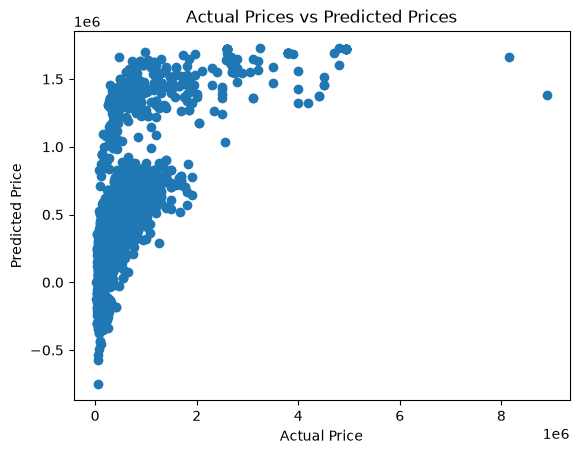

In [43]:
plt.scatter(Y_train, training_data_prediction)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual Prices vs Predicted Prices")
plt.show()

In [44]:
# Prediction on Test data
test_data_prediction = lin_reg_model.predict(X_test)

In [45]:
# R squared Error
error_score = metrics.r2_score(Y_test, test_data_prediction)
print("R squarred Error : ", error_score)

R squarred Error :  0.5212912933220218


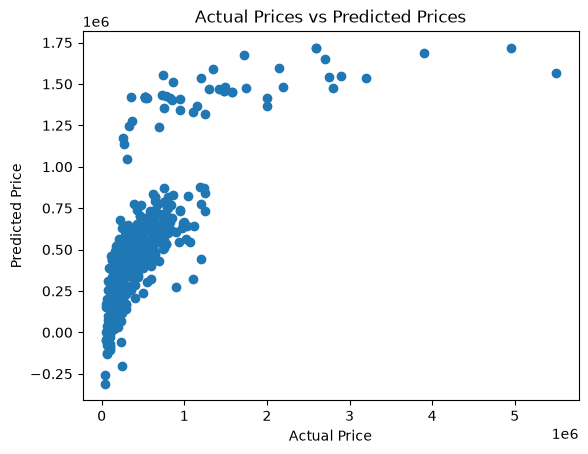

In [46]:
plt.scatter(Y_test, test_data_prediction)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual Prices vs Predicted Prices")
plt.show() 

2. Lasso Regressiom

In [47]:
# loading the linear regression model 
lass_reg_model = Lasso() 

In [48]:
lass_reg_model.fit(X_train, Y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [49]:
# Prediction on Training data
training_data_prediction = lass_reg_model.predict(X_train)

In [50]:
# R squared Error
error_score = metrics.r2_score(Y_train, training_data_prediction)
print("R squarred Error : ", error_score)

R squarred Error :  0.44307875874041414


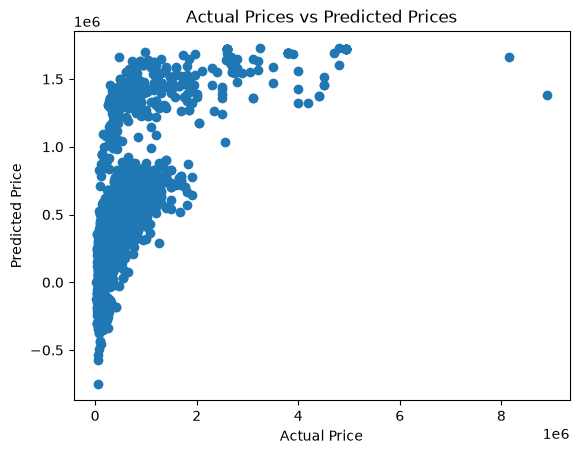

In [51]:
plt.scatter(Y_train, training_data_prediction)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual Prices vs Predicted Prices")
plt.show()

In [52]:
# Prediction on Test data
test_data_prediction = lin_reg_model.predict(X_test)

In [53]:
# R squared Error
error_score = metrics.r2_score(Y_test, test_data_prediction)
print("R squarred Error : ", error_score)

R squarred Error :  0.5212912933220218


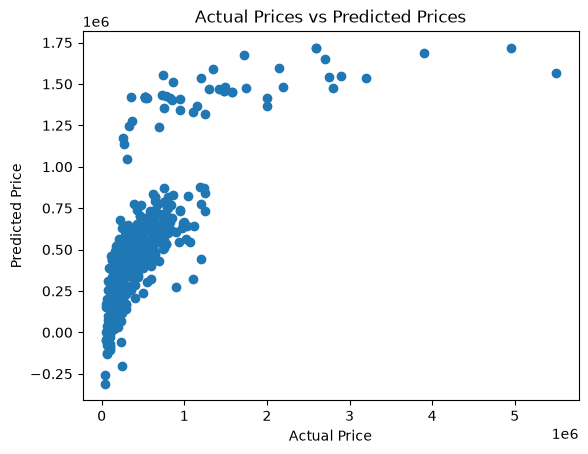

In [54]:
plt.scatter(Y_test, test_data_prediction)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual Prices vs Predicted Prices")
plt.show() 

### Quelques tests

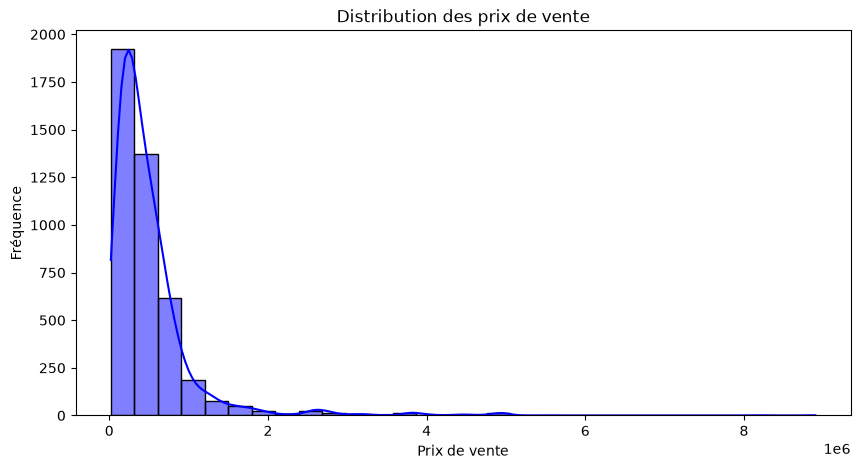

In [56]:
plt.figure(figsize=(10, 5))
sns.histplot(car_dataset['selling_price'], bins=30, kde=True, color='blue')
plt.title("Distribution des prix de vente")
plt.xlabel("Prix de vente")
plt.ylabel("Fréquence")
plt.show()

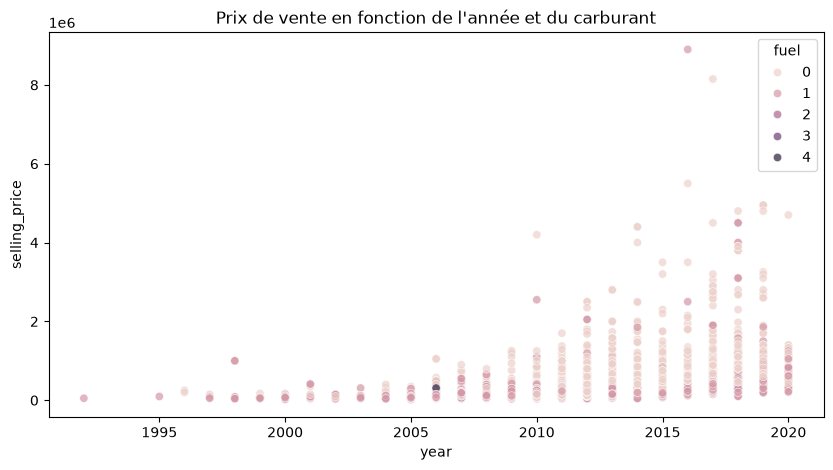

In [58]:
plt.figure(figsize=(10, 5))
sns.scatterplot(x='year', y='selling_price', data=car_dataset, hue='fuel', alpha=0.7)
plt.title("Prix de vente en fonction de l'année et du carburant")
plt.show()

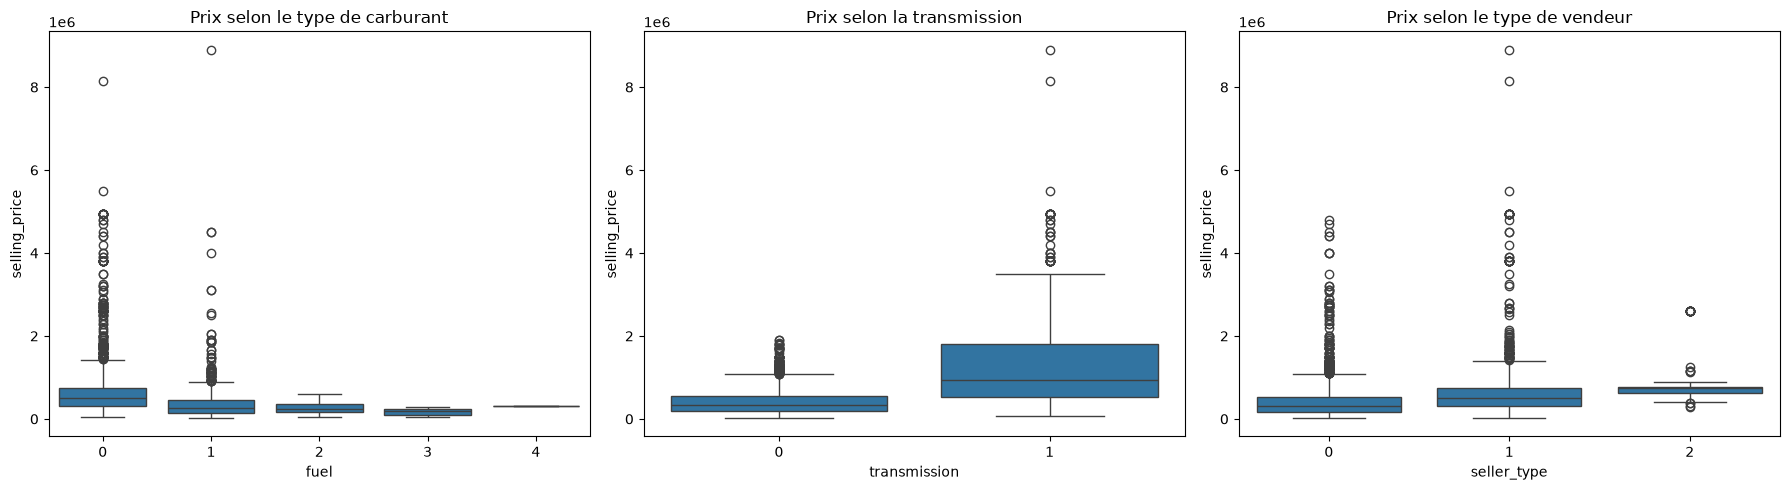

In [59]:
# Création de sous-graphiques pour comparer le carburant, la transmission et le vendeur
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(x='fuel', y='selling_price', data=car_dataset, ax=axes[0])
axes[0].set_title("Prix selon le type de carburant")

sns.boxplot(x='transmission', y='selling_price', data=car_dataset, ax=axes[1])
axes[1].set_title("Prix selon la transmission")

sns.boxplot(x='seller_type', y='selling_price', data=car_dataset, ax=axes[2])
axes[2].set_title("Prix selon le type de vendeur")

plt.tight_layout()
plt.show()

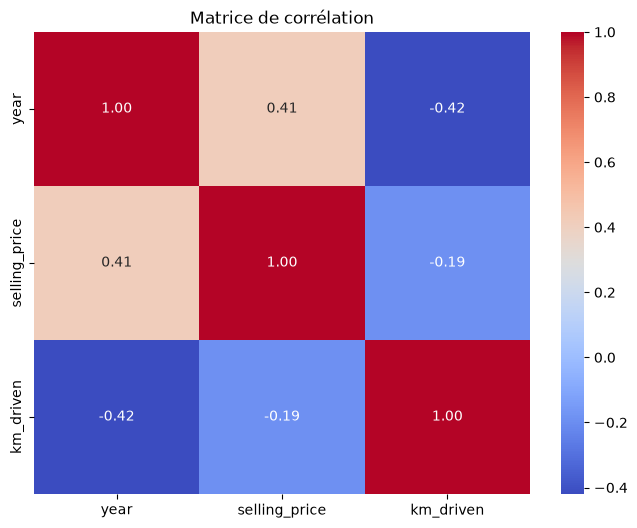

In [61]:
import numpy as np
plt.figure(figsize=(8, 6))
# On sélectionne uniquement les colonnes numériques pour la corrélation
numeric_df = car_dataset.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matrice de corrélation")
plt.show()

In [65]:
import numpy as np
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Créer la variable cible transformée
car_dataset['log_price'] = np.log1p(car_dataset['selling_price']) # log1p = log(x+1) pour éviter log(0)

# 2. Séparer X et Y
X = car_dataset.drop(['selling_price', 'log_price'], axis=1) # Mettez ici vos features encodées
Y = car_dataset['log_price']

# 3. Entraîner le modèle sur y transformé
# (N'oubliez pas de split train/test avant)
model = LinearRegression()
model.fit(X_train, Y_train)
Y_pred_log = model.predict(X_test)

# 4. Pour évaluer, on repasse les prédictions à l'échelle normale
Y_pred = np.expm1(Y_pred_log) # Inverse de log1p
Y_test_real = np.expm1(Y_test)

# 1. Créer la variable cible transformée
car_dataset['log_price'] = np.log1p(car_dataset['selling_price']) # log1p = log(x+1) pour éviter log(0)

# 2. Séparer X et Y
X = car_dataset.drop(['selling_price', 'log_price'], axis=1) # Mettez ici vos features encodées
Y = car_dataset['log_price']

# 3. Entraîner le modèle sur y transformé
# (N'oubliez pas de split train/test avant)
model = LinearRegression()
model.fit(X_train, Y_train)
Y_pred_log = model.predict(X_test)

# 4. Pour évaluer, on repasse les prédictions à l'échelle normale
Y_pred = np.expm1(Y_pred_log) # Inverse de log1p
Y_test_real = np.expm1(Y_test)

/tmp/ipykernel_8953/596319499.py:19: RuntimeWarning: overflow encountered in expm1
  Y_pred = np.expm1(Y_pred_log) # Inverse de log1p
/home/dilan/anaconda3/envs/ml/lib/python3.13/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: overflow encountered in expm1
  result = getattr(ufunc, method)(*inputs, **kwargs)
/tmp/ipykernel_8953/596319499.py:36: RuntimeWarning: overflow encountered in expm1
  Y_pred = np.expm1(Y_pred_log) # Inverse de log1p
/home/dilan/anaconda3/envs/ml/lib/python3.13/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: overflow encountered in expm1
  result = getattr(ufunc, method)(*inputs, **kwargs)
